In [1]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class
import math

from colossus.cosmology import cosmology
from colossus.halo import mass_adv

from scipy.integrate import quad

from scipy.interpolate import UnivariateSpline
import time
from numba import njit, prange

import matplotlib
from scipy.special import gamma as gamma_fn

from matplotlib.lines import Line2D


# fontsize for plots
matplotlib.rcParams['text.usetex'] = True
matplotlib.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
matplotlib.rcParams['lines.linewidth'] = 2
matplotlib.rcParams.update({'font.size': 20})

In [2]:
h = 0.6776
omega_m = 0.307
omega_b = 0.048
sigma_8 = 0.882531
n_s = 0.9665

c = 299792.458
Mpc = 3.2616*1e6*c*60**2*24*365.25 # km
H0_SI = h*100/Mpc # s^-1
G = 6.67430e-11 * 1e-9 # km^3 kg^-1 s^-2
Ms = 1.989e30 # kg
Gyr = 1e9* 60**2 * 24 * 365.25 # seconds


rho_c = 3. / 8 / np.pi * H0_SI**2 / (G/1e-9) # kg / m^3
rho_c = rho_c / Ms * (Mpc*1e3)**3 / h**2 # h**2 Ms/Mpc^3


cosmology.setCosmology('myCosmo', params=dict(H0 = h*100, Om0 = omega_m, Ob0 = omega_b, sigma8=sigma_8, ns=n_s))

In [3]:
# -----------------------
# Top-hat time evolution
# -----------------------

# Pure EdS analytic test (no CLASS)
@njit
def initial_cond_EdS(t0, M0, delta0, order=1):
    """
    In pure EdS, H(t) = 2/(3t), rho(t) = 1/(6*pi*G*t^2)
    Analytic δ_c = (3/20)*(12*pi)^(2/3) ≈ 1.686
    """
    # EdS parameters
    H_i = 2.0 / (3.0 * t0 * Gyr)  # s^-1
    rho_i = 1.0 / (6.0 * np.pi * G * (t0 * Gyr)**2) # kg/km^3         
    
        # LPT velocity expansion
    velocity_factor = 1.0 - delta0/3.0  # 1LPT (Zel'dovich)
    
    if order >= 2:
        velocity_factor -= 2.0 * delta0**2 / 21.0  # 2LPT
    
    if order >= 3:
        velocity_factor -= delta0**3 / 189.0  # 3LPT
    
    if order >= 4:
        velocity_factor -= delta0**4 / 2835.0  # 4LPT
    
    R0 = (3 * M0 * Ms/h / (4 * np.pi * rho_i * (1 + delta0)))**(1/3)  # km
    Rdot0 = H_i * R0 * velocity_factor  # km/s

    return R0/ Mpc*h, Rdot0 #, t_spane

@njit(fastmath=True, cache=False)
def lin_delta_EdS(times, delta0, t0):
    """
    Simple EdS linear extrapolation
    """
    
    delta_t = delta0 * (times / t0)**(2.0/3.0)
    return delta_t

# Helper: ddotR = - G * M_bound / R^2  (units: km/s^2)
@njit(fastmath=True, cache=False)
def ddotR(M_bound, R):
    if R <= 1e-30:
        return 0.0
    return - G * M_bound / R**2

@njit(fastmath=True, cache=False)
def RK4(Rdot, M_bound, R, dt):
    k1_r = Rdot
    k1_v = ddotR(M_bound, R)

    k2_r = Rdot + 0.5 * dt * k1_v
    k2_v = ddotR(M_bound, R + 0.5 * dt * k1_r)

    k3_r = Rdot + 0.5 * dt * k2_v
    k3_v = ddotR(M_bound, R + 0.5 * dt * k2_r)

    k4_r = Rdot + dt * k3_v
    k4_v = ddotR(M_bound, R + dt * k3_r)

    R_next = R + (dt / 6.0) * (k1_r + 2.0 * k2_r + 2.0 * k3_r + k4_r)
    Rdot_next = Rdot + (dt / 6.0) * (k1_v + 2.0 * k2_v + 2.0 * k3_v + k4_v)

    return R_next, Rdot_next


In [4]:
# # -----------------------
# # Physics: potential, P_bound, f_ret
# # -----------------------
@njit(fastmath=True)
def Phi_uniform(r, M, R):
    """
    Potential inside a uniform sphere at radius r:
    Phi(r) = - (G M / (2 R)) * (3 - (r/R)^2)
    """
    if R < 1e-30:
        return -1e30  # very deep potential
    return - (G * M / (2.0 * R)) * (3.0 - (r**2) / (R**2))

@njit(fastmath=True)
def P_bound_at_r(r, R, M, Rdot, v_k):
    """
    Fraction of kick directions at radius r that keep daughter bound.
    Returns number in [0,1].
    Pre-kick radial velocity magnitude at r: u = |(Rdot/R) * r|.
    """
    if R < 1e-30:
        return 1.0  # deep potential, everything bound
    u = abs(Rdot / R) * r   # km/s
    Phi = Phi_uniform(r, M, R)  # km^2/s^2 (negative)

    # Bound condition: 1/2 * (u^2 + v_k^2 + 2 u v_k cos) + Phi < 0
    # handle degenerate cases:
    if v_k == 0.0:
        return 1.0 if 0.5 * u**2 + Phi < 0 else 0.0
    if u == 0.0:
        return 1.0 if 0.5 * v_k**2 + Phi < 0 else 0.0

    # rearrange to cos < C
    C = (-2.0 * Phi - u**2 - v_k**2) / (2.0 * u * v_k)

    if C >= 1.0:
        return 1.0
    if C <= -1.0:
        return 0.0
    return 0.5 * (1.0 + C)


@njit(fastmath=True)
def f_ret_analytical(R, Rdot, M, v_k): 
    """
    Returns (f_inside, f_bound)
    """
    if R <= 1e-30:
        return 0.0, 0.0

    omega2 = G * M / R**3
    omega  = math.sqrt(omega2)
    xi     = v_k / (omega * R)
    beta   = math.fabs(Rdot) / (omega * R)
    xi2    = xi**2
    beta2  = beta**2


    # === f_inside: exact closed form ===
    f_inside = math.sqrt(max(0.0, 1.0 - xi2))

    # === f_bound: special cases ===

    # v_k = 0: A^2/R^2 = u^2(1+beta^2), no theta dependence
    if v_k == 0.0:
        u_crit2 = 3.0 / (1.0 + beta2)
        f_bound = min(1.0, u_crit2 ** 1.5)
        return f_inside, f_bound

    # Rdot = 0 (turnaround): A^2/R^2 = u^2 + xi^2, no theta dependence
    if beta == 0.0:
        rem = 3.0 - xi2
        f_bound = min(1.0, max(0.0, rem ** 1.5))
        return f_inside, f_bound

    # === f_bound: general case ===
    disc = 3.0 * (1.0 + beta2) - xi2
    if disc <= 0.0:
        # all particles unbound
        return f_inside, 0.0

    sqrt_disc = math.sqrt(disc)
    denom     = 1.0 + beta2
    u1        = (-beta * xi + sqrt_disc) / denom
    u2        = ( beta * xi + sqrt_disc) / denom

    # C_bound >= 1 everywhere in [0,1]: all bound
    if u1 >= 1.0:
        return f_inside, 1.0

    u1    = max(0.0, u1)
    u_top = min(1.0, u2)

    A = (3.0 - xi2) / (8.0  * beta * xi)
    B = denom       / (16.0 * beta * xi)

    F_top = u_top**3 / 6.0 + A * u_top**2 - B * u_top**4
    F_u1  = u1**3   / 6.0 + A * u1**2   - B * u1**4

    f_bound = u1**3 + 3.0 * (F_top - F_u1)
    f_bound = max(0.0, min(1.0, f_bound))

    return f_inside, f_bound

In [5]:
@njit
def evolve_top_hat_decay_v2(M0, R0, Rdot0, v_k, Gamma, t_spane, dt_initial, baryons=False):
    """
    Evolve the top-hat with decaying dark matter.
    Inputs:
      - M0 : initial parent mass (Msun)
      - R0  : initial radius (kpc)
      - Rdot0 : initial radial velocity of the shell (km/s)
      - v_k : kick magnitude (km/s)
      - epsilon : fraction of parent mass lost in decay (0..1)
      - Gamma : decay rate in 1/Gyr (Gamma = 1/tau)
      - t_spane, dt_Gyr : time integration parameters
    Returns:
      history : list of tuples (t, M_p, M_d, R, Rdot, f_ret)
    """

    # convert to SI
    R_ini = R0 * Mpc/h
    R = R_ini  # km
    Rdot = Rdot0    # km/s
    epsilon = v_k / (c+v_k)
    Gamma = Gamma / Gyr  # 1/s
    
    # initial compartments
    t, t_final = t_spane * Gyr
    dt_max = dt_initial * Gyr
    t = t_spane[0] * Gyr

    # M0 contains dcdm and baryon 
    if baryons:
        M_p = M0 * (omega_m-omega_b) / omega_m * Ms/h
        M_b = M0 * omega_b / omega_m * Ms/h
    else:
        M_p = M0 * Ms/h
        M_b = 0.0

    M_d      = 0.0
    M_ub     = 0.0
    M_b_Ms   = M_b / Ms*h

    # time-stepping loop
    steps = int(np.ceil((t_spane[1] - t_spane[0]) / dt_initial)) \
            + int(np.log(max(dt_initial/(1e-3*t_spane[0]), 1.0)) / 1e-3) + 10

    # decays before t0 (all daughters bound at such early times)
    pre = M_p * (1.0 - np.exp(-Gamma * t_spane[0] * Gyr))
    M_p = M_p - pre
    M_d = np.sqrt(1.0 - 2.0*epsilon) * pre

    history = np.zeros((steps, 6), dtype=float)
    history[0, 0] = t_spane[0]
    history[0, 1] = M_p/(Ms/h)
    history[0, 2] = M_d/(Ms/h)
    history[0, 3] = M_b_Ms
    history[0, 4] = R0
    history[0, 5] = Rdot

    total_step = 0
    for step in range(1, steps):
        dt = min(dt_max, 1e-3 * t)

        f_inside, f_bound = f_ret_analytical(R, Rdot, M_p + M_d + M_b + M_ub, v_k) 

        # Compute f_grav
        f_d = (M_d) / (M_p + M_d + M_b) if (M_p + M_d + M_b) > 0 else 0.0
        ff = f_inside/f_bound if f_bound > 1e-30 else 0.0
        f_grav = ff +  f_d * (1 - ff) 
        if f_grav > 1: f_grav = 1

        M_bound = M_p + f_grav*M_d + M_ub + M_b
        R_next, Rdot_next = RK4(Rdot, M_bound, R, dt)

        # Retained daughters
        decayed      = M_p * (1.0 - np.exp(-Gamma * dt))
        daughters    = np.sqrt(1.0 - 2.0 * epsilon) * decayed
        kept_bound   = daughters * f_bound

        t = t + dt
        R, Rdot = R_next, Rdot_next
        M_p = M_p - decayed
        M_d = M_d + kept_bound

        if v_k > 0:
            tau_esc = 0.75 * R / v_k                   # mean exit time from a uniform sphere
            M_ub = M_ub * np.exp(-dt / tau_esc) + (daughters - kept_bound)
        
        # record (convert to astrophysical units for convenience)
        M_p_Ms = M_p / Ms*h
        M_d_Ms = M_d / Ms*h
        R_Mpch = R / Mpc * h  # Mpc/h

        history[step, 0] = t / Gyr
        history[step, 1] = M_p_Ms
        history[step, 2] = M_d_Ms
        history[step, 3] = M_b_Ms
        history[step, 4] = R_Mpch
        history[step, 5] = Rdot

        total_step += 1
        if t+dt >= t_final or np.abs(R_next) < 0.01 * R_ini: 
            break

        # safety checks
        if R <= 0 or (M_p + M_d + M_b) <= 0:
            break

    return history[:total_step+1]

In [8]:
@njit
def t_of_z(z, Om=omega_m, h=h):
    """Cosmic time [Gyr] at redshift z, flat LCDM, no radiation."""
    OL = 1.0 - Om
    H0 = h * 100 / Mpc
    a = 1.0 / (1.0 + np.asarray(z))
    return 2.0 / (3.0 * H0 * np.sqrt(OL)) * np.arcsinh(np.sqrt(OL / Om) * a**1.5) / Gyr

@njit
def z_of_t(t, Om=omega_m, h=h):
    """Inverse: redshift at cosmic time t [Gyr]."""
    OL = 1.0 - Om
    H0 = h * 100 / Mpc
    a = (np.sinh(1.5 * H0 * np.sqrt(OL) * np.asarray(t) * Gyr) / np.sqrt(OL / Om))**(2/3)
    return 1.0 / a - 1.0

@njit
def find_delta0_numba(M0, t0, dt,
                    epsilon=0.001, v_k=0.0, Gamma=0.0,
                    delta0_low=0.001, delta0_high=0.05, z_collapse_target=0.0):
    
    t_at_zcollapse = t_of_z(z_collapse_target) 
    t_at_zeps = t_of_z(z_collapse_target + epsilon)

    t_spane = np.array([t0, t_at_zcollapse * 1.05])

    delta0_initial_low = delta0_low
    delta0_initial_high = delta0_high
    tolerance = 1e-6

    delta0_mid = 0.0
    t_collapse = 0.0
    z_collapse = 0.0
    M_collapse = 0.0

    for iteration in range(30):
        delta0_mid = (delta0_low + delta0_high) / 2.0 

        R0, Rdot0 = initial_cond_EdS(t0, M0, delta0_mid, order=4)
        
        hist = evolve_top_hat_decay_v2(M0, R0, Rdot0, v_k, Gamma, t_spane, dt)

        # Match original exactly
        t_collapse = hist[-1, 0]  # Last time
        M_p_array = hist[:, 1]    # Full array like original
        M_d_array = hist[:, 2]
        M_b_array = hist[:, 3]

        z_collapse = z_of_t(t_collapse)
        M_collapse = ((M_p_array + M_d_array + M_b_array))[-1]  # Last element

        # Check if within window
        if t_at_zeps < t_collapse < t_at_zcollapse:
            return 1.0, delta0_mid, t_collapse, z_collapse, M_collapse, delta0_low, delta0_high

        # Adjust bounds
        if t_collapse > t_at_zcollapse:
            delta0_low = delta0_mid
        else:
            delta0_high = delta0_mid

        # Check if hit bounds
        if np.abs(delta0_mid - delta0_initial_low) < tolerance:
            return 0.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0  # Failed

        if np.abs(delta0_mid - delta0_initial_high) < tolerance:
            return 0.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0  # Failed

    # Max iterations - return current best guess
    return 2.0, delta0_mid, t_collapse, z_collapse, M_collapse, delta0_low, delta0_high


@njit(parallel=True)
def compute_delta_c_core_parallel(M_list, t0, dt,
                                    epsilon, v_k, Gamma,
                                    delta0_low, delta0_high, z_collapse_target=0.0):
    """
    Numba-parallelized core computation for all masses.
    Returns arrays of results for each mass. 
    """
    n_masses = len(M_list)

    # Pre-allocate output arrays
    status_array = np.zeros(n_masses)
    delta0_array = np.zeros(n_masses)
    t_collapse_array = np.zeros(n_masses)
    z_collapse_array = np.zeros(n_masses)
    M_collapse_array = np.zeros(n_masses)
    delta_c_array = np.zeros(n_masses)

    # Parallel loop over masses
    for i in prange(n_masses):
        print(f'Mass index: {i}')
        M0 = M_list[i]

        # Find delta0 for this mass
        result = find_delta0_numba(M0, t0, dt,
                                    epsilon, v_k, Gamma,
                                    delta0_low, delta0_high, z_collapse_target)

        status, delta0_opt, t_collapse, z_collapse, M_collapse, _, _ = result

        # Store results
        status_array[i] = status
        delta0_array[i] = delta0_opt
        t_collapse_array[i] = t_collapse
        z_collapse_array[i] = z_collapse
        M_collapse_array[i] = M_collapse

        # Compute delta_c using linear theory
        if status == 1.0:  # Success 
            delta_c = lin_delta_EdS(t_collapse, delta0_opt, t0)
            delta_c_array[i] = delta_c
        elif status==2: # max iterations
            print('Warning: max iterations')
            delta_c = lin_delta_EdS(t_collapse, delta0_opt, t0)
            delta_c_array[i] = delta_c
        else:
            delta_c_array[i] = -1.0  # Mark as failed

    return status_array, delta0_array, t_collapse_array, z_collapse_array, M_collapse_array, delta_c_array


def compute_delta_c_vs_mass_numba(M_list, t0, dt, epsilon=0.001,
                            v_k=0, Gamma=0, 
                            delta0_low=0.001, delta0_high=0.05, z_collapse_target=0.0):
    """
    Compute delta_c as a function of mass M
    
    Uses Numba prange for parallel processing of multiple masses.
    
    Parameters:
    -----------
    M_list : array
        Array of halo masses in Msun/h
    t0 : float
        Initial time in Gyr
    dt : float
        Integration timestep in Gyr
    epsilon : float
        Target redshift window: epsilon < z_collapse < 0
    v_k, Gamma : float
        DDM parameters (0 for LCDM)
    delta0_low=0.001, 
    delta0_high=0.05, 
    z_collapse_target=0.0

    Returns:
    --------
    results : dict with arrays M_success, delta0_success, delta_c_success, z_collapse_success
            and lists of failed masses
    """
    print(f"\n{'='*70}")
    print(f"PARALLEL NUMBA COMPUTATION: {len(M_list)} masses")
    print(f"Parameters: v_k={v_k}, 1/Gamma={1/Gamma if Gamma > 0 else np.inf}")
    print(f"{'='*70}\n")

    # First call triggers JIT compilation
    print("Starting computation (first run compiles Numba functions)...")
    start_total = time.time()

    # Call parallel Numba function
    results_arrays = compute_delta_c_core_parallel(
        np.array(M_list), t0, dt,
        epsilon, v_k, Gamma,
        delta0_low, delta0_high, z_collapse_target
    )

    end_total = time.time()

    status_array, delta0_array, t_collapse_array, z_collapse_array, M_collapse_array, delta_c_array = results_arrays

    # Process results and filter successes/failures
    M0_success = []
    M_success = []
    delta0_success = []
    delta_c_success = []
    z_collapse_success = []
    M_failed = []
    M_maxiter = []

    for i, M0 in enumerate(M_list):
        status = status_array[i]

        if status == 0.0:  # Failed
            M_failed.append(M0)
        elif status == 2.0:  # Max iterations
            M_maxiter.append(M0)
            # Still store the result (best guess)
            M0_success.append(M0)
            M_success.append(M_collapse_array[i])
            delta0_success.append(delta0_array[i])
            delta_c_success.append(delta_c_array[i])
            z_collapse_success.append(z_collapse_array[i])
        else:  # status == 1.0, success
            M0_success.append(M0)
            M_success.append(M_collapse_array[i])
            delta0_success.append(delta0_array[i])
            delta_c_success.append(delta_c_array[i])
            z_collapse_success.append(z_collapse_array[i])

    # Summary
    print(f"\n{'='*70}")
    print(f"SUMMARY")
    print(f"{'='*70}")
    # print collapse time and redshift
    print(f't_coll: {t_collapse_array if len(t_collapse_array) > 0 else "None"} Gyr, z_coll: {z_collapse_array if len(z_collapse_array) > 0 else "None"}')
    print(f"Total time: {end_total - start_total:.2f} seconds")
    print(f"Time per mass: {(end_total - start_total)/len(M_list):.2f} seconds")
    print(f"Successful: {len(M0_success)}/{len(M_list)} masses")
    if M_maxiter:
        print(f"  Max iterations reached: {len(M_maxiter)} masses")
    if M_failed:
        print(f"   Failed: {len(M_failed)} masses")
        print(f"   Failed masses: {M_failed}")

    results = {
        'M0': np.array(M0_success),
        'M_collapse': np.array(M_success),
        'delta0': np.array(delta0_success),
        'delta_c': np.array(delta_c_success),
        'z_collapse': np.array(z_collapse_success),
        'M_failed': M_failed,
        'M_maxiter': M_maxiter
    }

    return results

In [9]:
DELTA_C_EDS = 3/20 * (12*np.pi)**(2/3)   # 1.686

def W_TH(x):
    return 3 * (np.sin(x) - x * np.cos(x)) / x**3

def sigma_integrand(k, M, lnPk, omega_m, c=1):
    R = (3 * M / (4 * np.pi * omega_m * rho_c))**(1/3) / c
    W = W_TH(k*R)
    return np.exp(lnPk(np.log(k))) * W**2 * k**2 / (2 * np.pi**2)  

def compute_sigma(M, Pk_spline, omega_m, c=1):
    sigma_squared, _ = quad(sigma_integrand, np.min(k_hdMpc), np.max(k_hdMpc), 
                           args=(M, Pk_spline, omega_m, c), epsrel=1.49e-13, limit=150)
    return np.sqrt(sigma_squared) 

def compute_dsigma_dM(M, Pk_spline, omega_m, c=1):
    sigma1 = compute_sigma(M, Pk_spline, omega_m, c=c)
    M2 = M * 1.0001
    sigma2 = compute_sigma(M2, Pk_spline, omega_m, c=c)
    return (sigma2 - sigma1) / (M2 - M)

def factor_fct(delta_c, sigma, model='ps', M_array=None, q=0.707, z=None):
    """
    Compute the multiplicity function factor
    
    Parameters:
    -----------
    delta_c : array, critical density (can be mass-dependent)
    sigma : array, variance σ(M)
    model : str, which model to use
    M_array : array, masses (required for 'st_excursion' model)
    
    Returns:
    --------
    f : multiplicity function factor
    """
    nu = delta_c / sigma

    if model in ['st', 'ts']:
        A = 0.3222
        p = 0.3
        # q = 1  #0.707  # 1 TS predicts 1 but simulations fit better with 0.707 1303.0839
        return np.sqrt(2/np.pi) * nu * A * np.sqrt(q) * (1 + (q*nu**2)**(-p)) * np.exp(-q*nu**2/2)

    elif model == 'tinker':
        if z is None:
            raise ValueError("model='tinker' needs z (Tinker+08 eqs. 5-8).")
        A0, a0, b0, c_tinker = 0.186, 1.47, 2.57, 1.19        # Table 2, Delta = 200 mean
        Delta = 200.
        alpha = 10**(-(0.75/np.log10(Delta/75.))**1.2)        # eq. 8, ~0.0107
        A = A0 * (1+z)**-0.14                                  # eq. 5
        a = a0 * (1+z)**-0.06                                  # eq. 6
        b = b0 * (1+z)**-alpha                                 # eq. 7  (c does not evolve)
        sigma_eff = sigma * DELTA_C_EDS / delta_c
        return A * ((sigma_eff/b)**(-a) + 1) * np.exp(-c_tinker / sigma_eff**2)

    else:  # 'ps' or default
        return np.sqrt(2/np.pi) * nu * np.exp(-nu**2/2)



CASTRO23 = {  # Table 4 of Castro et al. 2023 (A&A 671, A100)
    'rockstar': dict(a1=0.7962, a2=0.1449, az=-0.0658, p1=-0.5612, p2=-0.4743, q1=0.3688, q2=-0.2804, qz=0.0251),
    'ahf':      dict(a1=0.7937, a2=0.1119, az=-0.0693, p1=-0.5689, p2=-0.4522, q1=0.3652, q2=-0.2628, qz=0.0376),
    'subfind':  dict(a1=0.7953, a2=0.1667, az=-0.0642, p1=-0.6265, p2=-0.4907, q1=0.3215, q2=-0.2993, qz=0.0330),
    'velociraptor': dict(a1=0.7987, a2=0.1227, az=-0.0523, p1=-0.5912, p2=-0.4088, q1=0.3634, q2=-0.2732, qz=0.0715),
}

def Om_z_flat(z, Om0):
    x = Om0 * (1 + z)**3
    return x / (x + 1 - Om0)

def nu_f_castro23(nu, dlnsigma_dlnR, Om_z, finder='ahf'):
    P = CASTRO23[finder]
    s = dlnsigma_dlnR                                    # = 3 * dlnsigma/dlnM (negative)
    a = (P['a1'] + P['a2']*(s + 0.6125)**2) * Om_z**P['az']
    p =  P['p1'] + P['p2']*(s + 0.5)
    q = (P['q1'] + P['q2']*(s + 0.5)) * Om_z**P['qz']
    A = 1.0 / (2**(-0.5 - p + q/2) / np.sqrt(np.pi) * (2**p * gamma_fn(q/2) + gamma_fn(q/2 - p)))
    x2 = a * nu**2
    return A * np.sqrt(2*x2/np.pi) * np.exp(-x2/2) * (1 + x2**(-p)) * np.sqrt(x2)**(q - 1)


def compute_dndlnM(M_list, Pk_spline, omega_m, delta_c=DELTA_C_EDS, model='ps', c=1,
                   rho_c=rho_c, z=None, finder='ahf'):
    M_list = np.asarray(M_list)
    c_array = np.broadcast_to(np.atleast_1d(c), M_list.shape)   # raises if wrong length

    sigma = np.array([compute_sigma(M, Pk_spline, omega_m, c=ci) for M, ci in zip(M_list, c_array)])
    dsigma_dM = np.array([compute_dsigma_dM(M, Pk_spline, omega_m, c=ci) for M, ci in zip(M_list, c_array)])
    dlnsigma_dlnM = dsigma_dM * M_list / sigma

    if model == 'castro':
        if z is None:
            raise ValueError("model='castro' needs the redshift z (for Omega_m(z) and delta_c^KS).")
        if np.any(c_array != 1):
            raise ValueError("Castro+23 is calibrated with the top-hat filter (c=1).")
        Om_z = Om_z_flat(z, omega_m)
        delta_c_KS = DELTA_C_EDS * (1 + 0.0123*np.log10(Om_z))
        nu = delta_c * delta_c_KS / DELTA_C_EDS / sigma        # delta_c is EdS-normalised
        factor = nu_f_castro23(nu, 3*dlnsigma_dlnM, Om_z, finder=finder)
    else:
        factor = factor_fct(delta_c, sigma, model=model, z=z)

    dndlnM = omega_m * rho_c / M_list * factor * np.abs(dlnsigma_dlnM)
    return M_list, dndlnM


def compute_dndlnM_ddm(result_ddm, Pk_spline, omega_m, z=0.0, model='ps', c=1, rho_c=rho_c,
                       finder='ahf'):
    M0 = np.asarray(result_ddm['M0'])
    Mcoll = np.asarray(result_ddm.get('M_collapse', result_ddm.get('M_coll')))
    delta_c = np.asarray(result_ddm['delta_c'])

    c_array = np.broadcast_to(np.atleast_1d(c), M0.shape)   # raises if wrong length
    if model == 'castro' and np.any(c_array != 1):
        raise ValueError("Castro+23 is calibrated with the top-hat filter (c=1).")

    sigma = np.array([compute_sigma(M, Pk_spline, omega_m, c=ci) for M, ci in zip(M0, c_array)])
    dsigma_dM = np.array([compute_dsigma_dM(M, Pk_spline, omega_m, c=ci) for M, ci in zip(M0, c_array)])
    dlnsigma_dlnM = dsigma_dM * M0 / sigma

    if model == 'castro':
        # print('CASTRO')
        Om_z = Om_z_flat(z, omega_m)
        delta_c_KS = DELTA_C_EDS * (1 + 0.0123*np.log10(Om_z))
        nu = delta_c * delta_c_KS / DELTA_C_EDS / sigma
        factor = nu_f_castro23(nu, 3*dlnsigma_dlnM, Om_z, finder=finder)
    else:
        # print('DEFAULT:{}'.format(model))
        factor = factor_fct(delta_c, sigma, model=model, z=z)

    if np.any(np.diff(Mcoll) <= 0):
        raise ValueError("M_coll(M0) must be strictly increasing for the Jacobian.")
    jacobian = np.gradient(np.log(M0), np.log(Mcoll))

    dndlnM = omega_m * rho_c / M0 * factor * np.abs(dlnsigma_dlnM) * jacobian
    return Mcoll, dndlnM


def loglog_interp(x_new, x, y):
    """Log-log interpolation, NaN outside the tabulated range."""
    return np.exp(np.interp(np.log(x_new), np.log(x), np.log(y), left=np.nan, right=np.nan))

In [10]:
# LCDM Power spectrum

z_list = ['1.083', '0.000'] # '2.350', 

params = {'output': 'mPk',
        'P_k_max_h/Mpc' : 10,
        'z_max_pk' : 30,
    'Omega_cdm': omega_m - omega_b,
    'Omega_b': omega_b,
    'n_s': n_s,
    'h': h,
    'sigma8': sigma_8,
    'N_ncdm': 1,
    'background_ncdm_distribution': '0',
    'm_ncdm': '0.06',
    'N_ur': 2.0328,
    }

cosmo = Class()
cosmo.set(params)
cosmo.compute()

k_hdMpc = np.logspace(-3, 1, 1000)
k_1dMpc = k_hdMpc*h

Pk_lcdm_list = []
for z in z_list:
    Pk = np.array([cosmo.pk(ki, float(z)) for ki in k_1dMpc])
    Pk_lcdm_list.append(Pk)

output[i] -8.183614e-03 wanted 8.825310e-01 
output[i] -2.123774e-03 wanted 8.825310e-01 
output[i] 3.894639e-03 wanted 8.825310e-01 
output[i] 8.904693e-04 wanted 8.825310e-01 
output[i] 5.947975e-08 wanted 8.825310e-01 
output[i] -1.061218e-03 wanted 8.825310e-01 


In [11]:
# ═══════════════════════════════════════════════════════════════
# ANALYTICAL FORMULA 
# ═══════════════════════════════════════════════════════════════


# small mass plasteau
A=2.381604; beta=0.582017; gamma=0.564794

def log_fit4(log_x, log_A, beta, gamma):
    x = np.exp(log_x)
    base = log_A + beta*np.log(x) + (1 - gamma)*np.log(np.log(1 + x)) 
    return base 


# large mass plateau
def I_func(theta):
    return np.sin(theta) - 3*theta + 4*np.tan(theta/2)

def compute_J(Gt, theta_min=1e-6):
    def integrand(thp):
        if thp < 1e-8 or abs(thp - 2*np.pi) < 1e-8:
            return 0.0
        t_dimless = (thp - np.sin(thp)) / np.pi
        decay = 1.0 - np.exp(-Gt * t_dimless)
        return (np.sin(thp) * decay / (1 - np.cos(thp))**2
                * (-6*np.pi - I_func(thp)))
    J, _ = quad(integrand, theta_min, 2*np.pi, limit=200, epsrel=1e-12)
    return J

def analytical_delta_c(eps, Gt, dc_eds, J=None, theta_min=1e-6):
    """
    First-order perturbative prediction:
        delta_c = dc_eds * (1 + phi^3 / (18*pi))
    where phi^3 = -4 * eps * J(Gt)
    """
    if J is None:
        J = compute_J(Gt, theta_min)
    phi3 = -6.0 * eps * J
    return dc_eds * (1.0 + phi3 / (18.0 * np.pi)), J




# intermediate mass
def make_fit_func(delta_0, delta_inf, delta_eds):
    y0_exc   = delta_0   - delta_eds
    yinf_exc = delta_inf - delta_eds
    def fit(logM, logM1, ratio):
        alpha1 = 1./2
        alpha2 = 4
        logM2 = np.log10(10**logM1 * ratio)
        nu1 = 0.1586
        x  = 10**(alpha1 * (logM - logM1))
        x2 = 10**(alpha2 * (logM - logM2))
        exc = yinf_exc + (y0_exc - yinf_exc) / ((1.0 + x)*(1.0 + x2))**nu1
        return np.log(exc)          # ← fit log(excess)
    return fit


def logM1_model(log_vk, log_tta):
    return 0.924 + 3*log_vk + log_tta

def logratio_model(log_Gt):
    return 3.454 - 0.881 * log_Gt - 0.450 * (log_Gt)**2


# f_bound analytic
def compute_omega_m_eff_semianalytic(Gamma, v_k, omega_m, M_list,
                                      sigma_list, dsigmadM_list,
                                      t_c=13.8, model='st'):

    epsilon = v_k / (v_k+c)
    Gtilde      = Gamma * t_c / 2
    t_ta_s      = (t_c / 2) * Gyr
    parent_frac = np.exp(-Gamma * t_c)
    norm        = (1 - np.exp(-2 * Gtilde)) * np.pi / Gtilde

    def fbound_bar(M0_Msun_h):
        M0_kg  = M0_Msun_h * Ms / h
        R_ta   = (8 * G * M0_kg * t_ta_s**2 / np.pi**2)**(1/3)  # km

        def integrand(theta):
            R    = (R_ta / 2) * (1 - np.cos(theta))          # km
            Rdot = (np.pi * R_ta * np.sin(theta) /
                    (2 * t_ta_s * (1 - np.cos(theta))))       # km/s
            _, fb   = f_ret_analytical(R, Rdot, M0_kg, v_k)
            Gamma_t = Gtilde * (theta - np.sin(theta)) / np.pi
            return fb * np.exp(-Gamma_t) * (1 - np.cos(theta))

        num, _ = quad(integrand, 1e-6, 2*np.pi-1e-6 , limit=200)
        return num / norm

    ratio_list   = np.array([parent_frac + np.sqrt(1-2*epsilon) * (1 - parent_frac) * fbound_bar(M0)
                              for M0 in M_list])
    lcdm_weights = np.abs(dsigmadM_list) / sigma_list * factor_fct(1.686, sigma_list, model=model)
    return ratio_list , omega_m * np.average(ratio_list, weights=M_list * lcdm_weights)


In [12]:
z_list =  [0, 1.083]  
Gamma_eps_list = [[0, 0], [1/10., 1250], [1/5., 625], [1/20., 625.], [1/20., 2250]] 
M_list = np.logspace(14, 16, 32)

results_dict_final = {}
dt = 2e-5
t0 = 1e-6

for z in z_list:
    for Gamma, v_k in Gamma_eps_list:
        print(f"Computing for z={z}, Gamma={Gamma:.4f}, v_k={v_k}")
        results = compute_delta_c_vs_mass_numba(
            M_list, t0=t0, dt=dt,
            epsilon=0.0001, v_k=v_k, Gamma=Gamma,
            delta0_low=1e-6, delta0_high=0.05, 
            z_collapse_target=z
        )
        results_dict_final[(z, Gamma, v_k)] = results

Computing for z=0, Gamma=0.0000, v_k=0

PARALLEL NUMBA COMPUTATION: 32 masses
Parameters: v_k=0, 1/Gamma=inf

Starting computation (first run compiles Numba functions)...
Mass index: 0Mass index: 15
Mass index: 28
Mass index: 3

Mass index: 18
Mass index: 24
Mass index: 9
Mass index: 26
Mass index: 12
Mass index: 6
Mass index: 21
Mass index: 30
Mass index: 16
Mass index: 31
Mass index: 7
Mass index: 13
Mass index: 1
Mass index: 10
Mass index: 27
Mass index: 19
Mass index: 4
Mass index: 25
Mass index: 29
Mass index: 22
Mass index: 17
Mass index: 8
Mass index: 11
Mass index: 2
Mass index: 20
Mass index: 14
Mass index: 5
Mass index: 23

SUMMARY
t_coll: [13.82237123 13.82237123 13.82237123 13.82237123 13.82237123 13.82237123
 13.82237123 13.82237123 13.82237123 13.82237123 13.82237123 13.82237123
 13.82237123 13.82237123 13.82237123 13.82237123 13.82237123 13.82237123
 13.82237123 13.82237123 13.82237123 13.82237123 13.82237123 13.82237123
 13.82237123 13.82237123 13.82237123 13.82237123 1

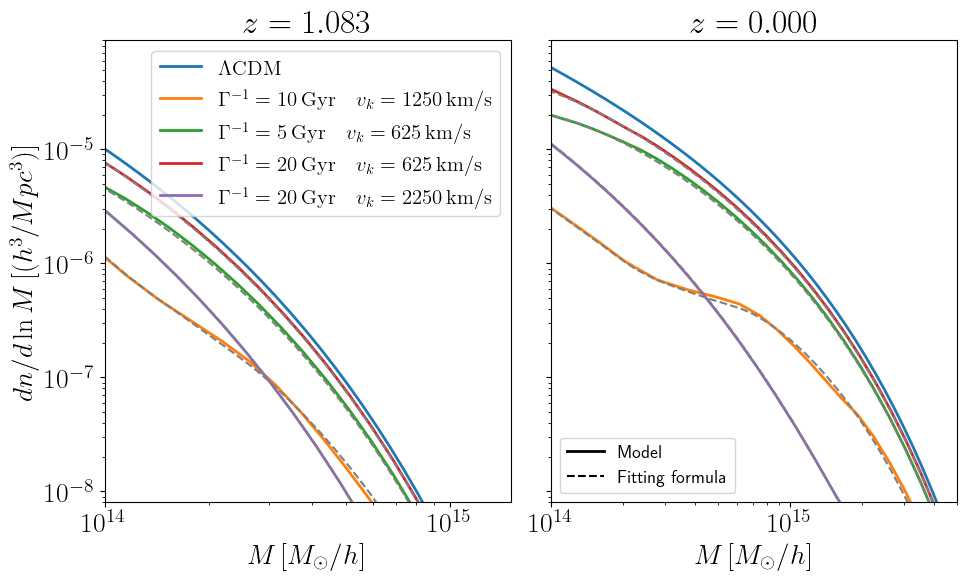

In [13]:
def castro_lcdm_200m(M200m, Pk_spline, z, c_model='diemer19'):
    """Castro+23 (AHF) LCDM HMF, converted from M_vir to M200m with a LCDM c(M)."""
    Mvir, _, _ = mass_adv.changeMassDefinitionCModel(M200m, z, '200m', 'vir', c_model=c_model)
    _, n_vir = compute_dndlnM(Mvir, Pk_spline, omega_m, model='castro', c=1, z=z, finder='ahf')
    jac = np.gradient(np.log(Mvir), np.log(M200m))  # dlnMvir/dlnM200m
    return n_vir * jac

z_vals  = [1.083, 0]                 # same values as used to build results_dict_final
z_labs  = ['1.083', '0.000']         # for file names

Gamma_eps_list = [[1/10., 1250], [1/5., 625], [1/20., 625.], [1/20., 2250]]   # same values as in results_dict_final
M_lcdm = np.logspace(12, 16, 100)
M_fit  = np.logspace(13, 16.5, 80)   # grid for the fitting-formula curves

colors = ['C0', 'C1', 'C2', 'C3', 'C4']
labels = [r'$\Gamma^{-1}=0\quad v_k=0$',
          r'$\Gamma^{-1}=10\,\mathrm{Gyr}\quad v_k=1250\,\mathrm{km/s}$',
          r'$\Gamma^{-1}=5\,\mathrm{Gyr}\quad v_k=625\,\mathrm{km/s}$',
          r'$\Gamma^{-1}=20\,\mathrm{Gyr}\quad v_k=625\,\mathrm{km/s}$',
          r'$\Gamma^{-1}=20\,\mathrm{Gyr}\quad v_k=2250\,\mathrm{km/s}$']


fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharex='col',
                         gridspec_kw={'hspace': 0.05}, sharey='row')

for j, z in enumerate(z_vals):
    Pk_spline = UnivariateSpline(np.log(k_hdMpc), np.log(Pk_lcdm_list[j]*h**3), s=0)
    t_ta   = t_of_z(z) / 2
    dc_ref = results_dict_final[(z, 0, 0)]['delta_c'][0]      # pipeline LCDM reference

    # LCDM: ST with the pipeline reference (for the response) and Castro baseline
    dndlnM_lcdm_ts = compute_dndlnM(M_lcdm, Pk_spline, omega_m, delta_c=dc_ref, model='ts', c=1, z=z)
    dndlnM_castro  = castro_lcdm_200m(M_lcdm, Pk_spline, z=z)
    to_castro = lambda Mc, n: n / loglog_interp(Mc, dndlnM_lcdm_ts[0], dndlnM_lcdm_ts[1]) \
                                * loglog_interp(Mc, M_lcdm, dndlnM_castro)

    # sigma on the fit grid (needed for the semi-analytic M_coll)
    sig_f  = np.array([compute_sigma(M, Pk_spline, omega_m, c=1) for M in M_fit])
    dsig_f = np.array([compute_dsigma_dM(M, Pk_spline, omega_m, c=1) for M in M_fit])

    for i in range(len(labels)):
        # --- theory ---
        if i == 0:
            Mc_num, n_num = M_lcdm, dndlnM_castro
            axes[j].loglog(Mc_num, n_num, '-', lw=2, color=colors[i], label=r'$\Lambda\mathrm{CDM}$')
        else:
            Gamma, v_k = Gamma_eps_list[i-1]
            key = (z, Gamma, v_k)

            # numerical (solid)
            Mc_n, n_n = compute_dndlnM_ddm(results_dict_final[key], Pk_spline, omega_m, model='ts', c=1, z=z)
            Mc_num, n_num = Mc_n, to_castro(Mc_n, n_n)
            axes[j].loglog(Mc_num, n_num, '-', lw=2, color=colors[i], label=labels[i])

            # fitting formula (dashed): delta_c fit + semi-analytic M_coll
            delta_0 = np.exp(log_fit4(np.log(Gamma*t_ta), np.log(A), beta, gamma)) + dc_ref
            delta_inf, _ = analytical_delta_c(v_k/(v_k+c), Gamma*t_ta, dc_ref)
            fit_func = make_fit_func(delta_0, delta_inf, dc_ref)
            log_Gt, log_tta = np.log10(Gamma*t_ta), np.log10(t_ta)
            logM1, logratio = logM1_model(np.log10(v_k), log_tta), logratio_model(log_Gt)
            dc_fit = np.exp(fit_func(np.log10(M_fit), logM1, 10**logratio)) + dc_ref
            r_th, _ = compute_omega_m_eff_semianalytic(Gamma, v_k, omega_m, M_fit, sig_f, dsig_f,
                                                       t_c=2*t_ta, model='st')
            Mc_f, n_f = compute_dndlnM_ddm({'M0': M_fit, 'M_collapse': r_th*M_fit, 'delta_c': dc_fit},
                                           Pk_spline, omega_m, model='ts', c=1, z=z)
            axes[j].loglog(Mc_f, to_castro(Mc_f, n_f), '--', lw=1.5, color='gray')

    axes[j].set_title(f'$z={z_labs[j]}$')
    axes[j].set_xlabel(r'$M\, [M_\odot/h]$')


axes[0].legend(fontsize=15)
axes[1].legend([Line2D([0], [0], color='k', lw=2, ls='-'), Line2D([0], [0], color='k', lw=1.5, ls='--')],
                  ['Model', 'Fitting formula'], fontsize=13, loc='lower left')
axes[0].set_ylabel(r'$dn/d\ln M\, [(h^3/Mpc^3)]$')

axes[0].set_xscale('log')
axes[0].set_yscale('log')

axes[0].set_ylim(8e-9, 9e-5); 
axes[0].set_xlim(1e14, 1.5e15)
axes[1].set_xlim(1e14, 5e15)

fig.subplots_adjust(wspace=0.1)
plt.savefig('hmf_castro_final.pdf', bbox_inches='tight')